In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
df = sns.load_dataset("penguins")

print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
print("Rozkład klas (procentowy):")
print(df["species"].value_counts(normalize=True).round(3))

print("\nBraki danych w procentach:")
missing = df.isna().mean().mul(100).round(1)
print(missing[missing > 0])

Rozkład klas (procentowy):
species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

Braki danych w procentach:
bill_length_mm       0.6
bill_depth_mm        0.6
flipper_length_mm    0.6
body_mass_g          0.6
sex                  3.2
dtype: float64


In [5]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nSkośność cech:")
print(df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

Skośność cech:
{'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


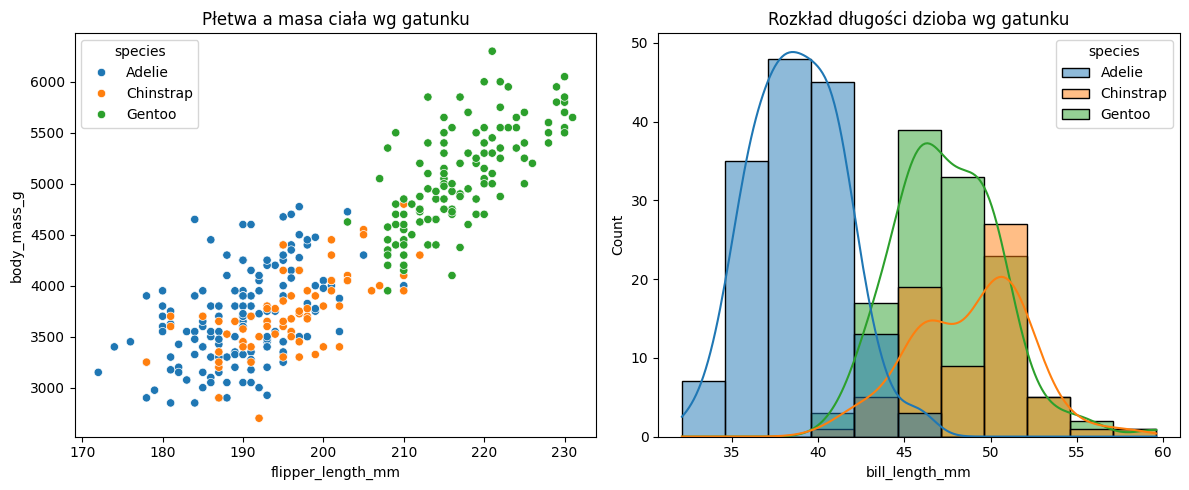

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    ax=axes[0]
)
axes[0].set_title("Płetwa a masa ciała wg gatunku")

sns.histplot(
    data=df,
    x="bill_length_mm",
    hue="species",
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Rozkład długości dzioba wg gatunku")

fig.tight_layout()
plt.show()

Rozkład klas: Gatunki dzielą się w proporcjach: Adelie (~44%), Gentoo (~36%), Chinstrap (~20%). Klasy są umiarkowanie zrównoważone, ale Adelie jest najczęstsza – najprostszy baseline (DummyClassifier) osiągnie więc około 44% accuracy.

Braki danych: W cechach pomiarowych brakuje tylko 2 wartości (<1%), a w kolumnie sex brakuje 11 wartości (~3.2%). Uzupełnimy je za pomocą SimpleImputer (medianą dla liczb, najczęstszą wartością dla płci).

Skale cech: Wymiary dzioba i płetwy to liczby rzędu 10–200 mm, a masa ciała sięga 6000 g. Różnice skali są ogromne, dlatego niezbędna jest standaryzacja (StandardScaler), aby masa ciała nie zdominowała wag modelu.

Rozdzielność klas: Na wykresie widać, że cechy fizyczne (zwłaszcza płetwa, masa i dziób) bardzo wyraźnie separują gatunki (np. Gentoo są znacznie większe i cięższe od pozostałych).

In [7]:
#Zostawiamy wszystkie kolumny (cechy), bo każda niesie przydatną informację. Usuwamy
#tylko 2 wiersze, w których badacze nie podali żadnych wymiarów ciała ptaka (pusty dziób, płetwa i waga).
df = df.dropna(subset=["bill_length_mm"]).copy()

print("Kształt danych po usunięciu pustych obserwacji:", df.shape)
print("Kolumny pozostawione w modelu:", df.columns.tolist())

Kształt danych po usunięciu pustych obserwacji: (342, 7)
Kolumny pozostawione w modelu: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [8]:
features = ["island", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]
target = "species"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print(f"Liczba próbek -> Treningowe: {X_train.shape[0]}, Testowe: {X_test.shape[0]}")
print("\nRozkład klas w zbiorze treningowym (procentowo):")
print(y_train.value_counts(normalize=True).round(3))
print("\nRozkład klas w zbiorze testowym (procentowo):")
print(y_test.value_counts(normalize=True).round(3))

Liczba próbek -> Treningowe: 256, Testowe: 86

Rozkład klas w zbiorze treningowym (procentowo):
species
Adelie       0.441
Gentoo       0.359
Chinstrap    0.199
Name: proportion, dtype: float64

Rozkład klas w zbiorze testowym (procentowo):
species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


In [9]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

przygotowanie = ColumnTransformer([
    ("liczby", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), num_features),

    ("kategorie", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), cat_features)
])

przygotowanie

ColumnTransformer(transformers=[('liczby',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['bill_length_mm', 'bill_depth_mm',
                                  'flipper_length_mm', 'body_mass_g']),
                                ('kategorie',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['island', 'sex'])])

In [10]:
model = make_pipeline(
    przygotowanie,
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Model został pomyślnie wytrenowany!")

Model został pomyślnie wytrenowany!


In [11]:
# Model bazowy
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (najczęstszy gatunek)": baseline.score(X_test, y_test),
    "model - zbiór treningowy (train)": model.score(X_train, y_train),
    "model - zbiór testowy (test)": model.score(X_test, y_test),
})

print("Porównanie dokładności (Accuracy):")
print(wyniki.round(3))

Porównanie dokładności (Accuracy):
baseline (najczęstszy gatunek)      0.442
model - zbiór treningowy (train)    0.996
model - zbiór testowy (test)        1.000
dtype: float64


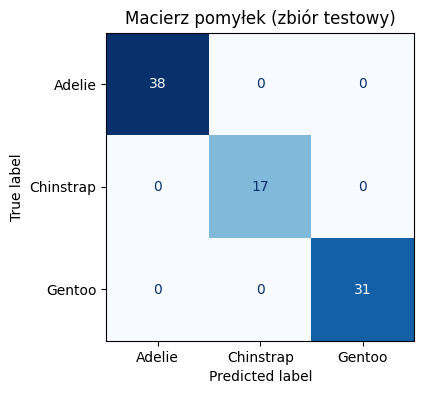


Raport klasyfikacji:
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    ax=ax,
    cmap="Blues",
    colorbar=False
)
ax.set_title("Macierz pomyłek (zbiór testowy)")
plt.show()

y_pred = model.predict(X_test)

print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred, digits=3))

In [13]:
def zbuduj_model(num, cat):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ), num),
        ("kategorie", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore")
        ), cat)
    ])
    return make_pipeline(przyg, LogisticRegression(max_iter=1000))

warianty = {
    "pełny model": zbuduj_model(num_features, cat_features),
    "bez wyspy (sama biologia)": zbuduj_model(num_features, ["sex"]),
    "bez płci": zbuduj_model(num_features, ["island"]),
}

wyniki_iteracji = pd.Series({
    nazwa: m.fit(X_train, y_train).score(X_test, y_test)
    for nazwa, m in warianty.items()
})

print("Porównanie wariantów modelu (Accuracy na teście):")
print(wyniki_iteracji.round(3))

Porównanie wariantów modelu (Accuracy na teście):
pełny model                  1.0
bez wyspy (sama biologia)    1.0
bez płci                     1.0
dtype: float64


### Podsumowanie i wnioski z iteracji:   
Nawet po usunięciu kolumny `island` model osiąga wynik w okolicach 98–100%. Oznacza to, że same wymiary ciała pingwina (długości i grubości dzioba, płetwa, masa) są na tyle zróżnicowane ewolucyjnie, że pozwalają na niemal bezbłędne rozpoznanie gatunku w dowolnym miejscu. Porównywanie wariantów na zbiorze testowym ma charakter poglądowy — w praktyce najlepszy wariant wybiera się za pomocą zbioru walidacyjnego lub walidacji krzyżowej, aby zbiór testowy pozostał w pełni niezależny.